## Estimating Equilibrium Climate Sensitivity (ECS) in CMIP6 Models

**Adapted from** https://github.com/pangeo-gallery/cmip6/blob/master/ECS_Gregory_method.ipynb

In this exercise, you will be estimating the Equilibrium Climate Sensitivity (ECS) of the CMIP6 models using the ["Gregory Method"](https://agupubs.onlinelibrary.wiley.com/doi/epdf/10.1029/2003GL018747). ECS is defined as the change in global mean near surface air temperature (tas) due to a doubling of CO$_{2}$ concentrations, once the climate system has reached equilibrium (i.e. the net radiative imbalance at the top-of-atmosphere (TOA) is zero). You will be working with global, annual mean tas and TOA radiation data from the `abrupt-4xCO2` and `piControl` experiments in the CMIP6 archive. We would typically use the `abrupt-2xCO2` data for this method, but we'll be using `abrupt-4xCO2` because there is more data available. The global mean data will be provided to you in a netCDF format, to save time, but you will also use the downloaded data from Lab 1. In the end, you will be creating a 4-panel plot, comparing the timeseries of global mean temperature and radiative imbalance across the models, as well as the spread in ECS across the CMIP6 ensemble.

### Required Files

+ abrupt-4xCO2_global_annual_means.nc
+ full_abrupt-4xCO2_global_annual_means.nc

### Load CMIP6 global mean data

The first step will be to grab the global mean data for the `abrupt-4xCO2` and `piControl` experiments (which has already been downloaded and pre-processed, using the methods from the previous module). The dataset contains the following variables for each model (`source_id`) and experiment (`experiment_id`):

+ `tas` - near surface air temperature (K)
+ `rsdt` - incoming shortwave radiation at the TOA (W m$^{-2}$)
+ `rsut` - outgoing (reflected) shortwave radiation at the TOA (W m$^{-2}$)
+ `rlut` - outgoing longwave radiation at the TOA (W m$^{-2}$)

In [1]:
### Load the necessary packages ###
from matplotlib import pyplot as plt
import xarray as xr
import numpy as np

### Load CMIP6 data from nc file ###
CMIP6_fil = '../Lab1/abrupt-4xCO2_global_annual_means.nc'
big_ds = xr.open_dataset(CMIP6_fil)

big_ds

<xarray.Dataset> Size: 200kB
Dimensions:        (source_id: 3, experiment_id: 2, year: 1000)
Coordinates:
  * source_id      (source_id) <U9 108B 'CanESM5' 'GFDL-ESM4' 'INM-CM4-8'
  * experiment_id  (experiment_id) <U12 96B 'abrupt-4xCO2' 'piControl'
  * year           (year) float64 8kB 0.0 1.0 2.0 3.0 ... 997.0 998.0 999.0
Data variables:
    tas            (source_id, experiment_id, year) float64 48kB ...
    rsut           (source_id, experiment_id, year) float64 48kB ...
    rlut           (source_id, experiment_id, year) float64 48kB ...
    rsdt           (source_id, experiment_id, year) float64 48kB ...
Attributes: (12/59)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-4xco2
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    version:                     v20190429
    axis:                        Y
    bounds:                      lat_bnds
    long_name:                   Latitude
    standard_name:               latitude
    units:                       degrees_north

### Calculate Derived Variables

Before we can estimate ECS, we need to calculate two derived quantities:

1) The net radiative imbalance at the TOA, which is the incoming shortwave radiation minus the outgoing shortwave and longwave radiation (imbalance = rsdt - rsut - rlut). A positive imbalance means the Earth is gaining energy.
2) The anomaly of the `abrupt-4xCO2` run compared to the `piControl` run. We calculate the long-term mean of the `piControl` run for each model, and subtract it from both experiments. This removes each model's own baseline climate, so that we are only looking at the response to the CO$_{2}$ forcing.

In [2]:
### Calculate the net radiative imbalance at the TOA ###
big_ds['imbalance'] = big_ds['rsdt'] - big_ds['rsut'] - big_ds['rlut'] # incoming shortwave - outgoing shortwave - outgoing longwave

### Calculate anomalies relative to the piControl run ###
ds_mean = big_ds[['tas', 'imbalance']].sel(experiment_id='piControl').mean(dim='year') # long-term piControl mean for each model
ds_anom = big_ds[['tas', 'imbalance']] - ds_mean # subtract the piControl mean from both experiments

### Add some metadata ###
ds_anom.tas.attrs['long_name'] = 'Global Mean Surface Temp Anom'
ds_anom.tas.attrs['units'] = 'K'
ds_anom.imbalance.attrs['long_name'] = 'Global Mean Radiative Imbalance'
ds_anom.imbalance.attrs['units'] = 'W m$^{-2}$'

ds_anom

<xarray.Dataset> Size: 104kB
Dimensions:        (year: 1000, experiment_id: 2, source_id: 3)
Coordinates:
  * year           (year) float64 8kB 0.0 1.0 2.0 3.0 ... 997.0 998.0 999.0
  * experiment_id  (experiment_id) <U12 96B 'abrupt-4xCO2' 'piControl'
  * source_id      (source_id) <U9 108B 'CanESM5' 'GFDL-ESM4' 'INM-CM4-8'
Data variables:
    tas            (source_id, experiment_id, year) float64 48kB 1.262 ... nan
    imbalance      (source_id, experiment_id, year) float64 48kB 6.833 ... nan
Attributes: (12/59)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-4xco2
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    version:                     v20190429
    axis:                        Y
    bounds:                      lat_bnds
    long_name:                   Latitude
    standard_name:               latitude
    units:                       degrees_north

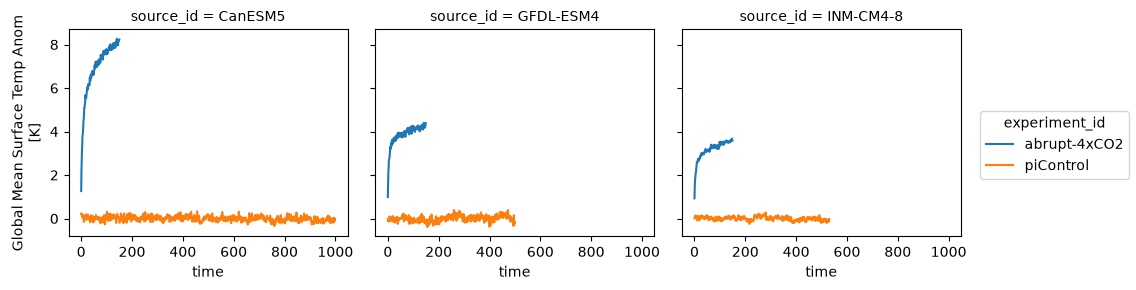

In [3]:
ds_anom.tas.plot.line(col='source_id', x='year', col_wrap=3)

### Select the first 150 years

The models cover different time intervals, so we are going to limit our analysis to the first 150 years after the abrupt quadrupling of $CO_{2}$ (the standard period used for the Gregory Method). Note that the units of 'tas' are now an anomaly in degrees Kelvin, and 'imbalance' is in $W m^{-2}$:

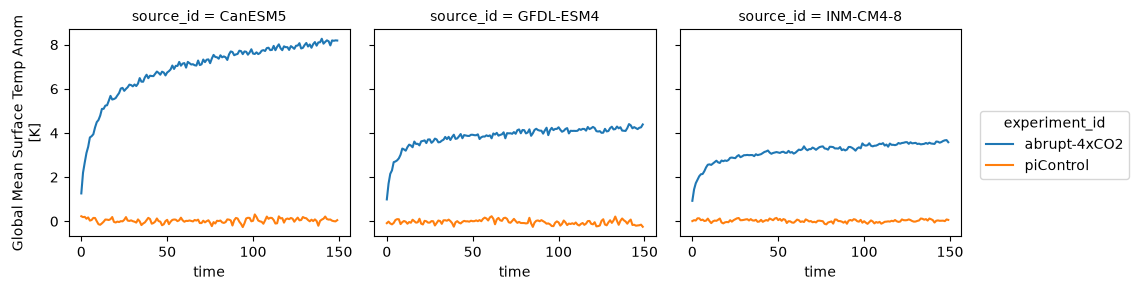

In [4]:
### Select the first 150 years of the abrupt-4xCO2 experiment ###
first_150_years = slice(0, 149)
ds_anom.tas.sel(year=first_150_years).plot.line(col='source_id', x='year', col_wrap=3)

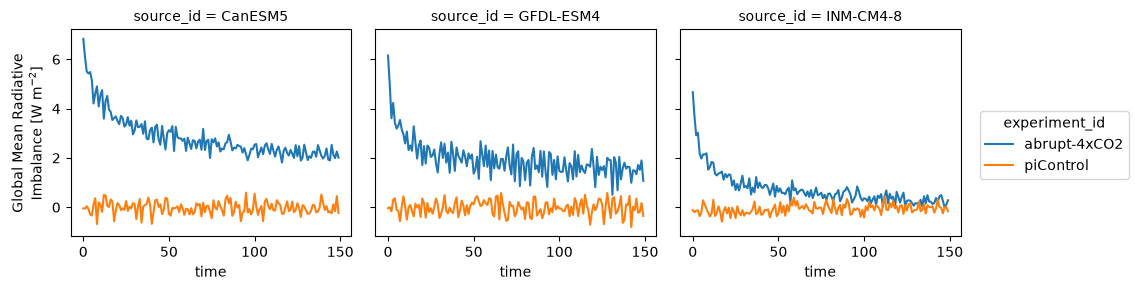

In [5]:
ds_anom.imbalance.sel(year=first_150_years).plot.line(col='source_id', x='year', col_wrap=3)

### Calculate ECS

Right after CO$_{2}$ is quadrupled, there is a large positive radiative imbalance at the TOA. As the planet warms, it radiates more energy back to space, so the imbalance shrinks over time. If we plot the imbalance ($N$) against the temperature anomaly ($\Delta T$), we get a roughly straight line:

$$N = F + \lambda \Delta T$$

where the intercept $F$ is the radiative forcing from 4xCO$_{2}$, and the slope $\lambda$ is the climate feedback parameter (which is negative). The line crosses $N = 0$ (equilibrium) at $\Delta T = -F/\lambda$, which is the equilibrium warming for a quadrupling of CO$_{2}$. Since the radiative forcing of CO$_{2}$ is roughly a logarithmic function of its concentration, a quadrupling is two doublings, so we divide this by 2 to get the ECS. We will fit this line for each model using `np.polyfit`:

In [6]:
### Create function to calculate ECS for each model ###
ds_abrupt = ds_anom.sel(year=first_150_years, experiment_id='abrupt-4xCO2').reset_coords(drop=True)

def calc_ecs(ds):
    # Each group keeps a length-1 source_id dimension, but polyfit needs 1D data.
    # Some sources don't have all 150 years, drop those missing values.
    ds = ds.squeeze('source_id').dropna('year')
    a, b = np.polyfit(ds.tas, ds.imbalance, 1)
    ecs = -0.5 * (b/a)
    return xr.DataArray(ecs)

ds_abrupt['ecs'] = ds_abrupt.groupby('source_id').map(calc_ecs)
ds_abrupt

<xarray.Dataset> Size: 9kB
Dimensions:    (year: 150, source_id: 3)
Coordinates:
  * year       (year) float64 1kB 0.0 1.0 2.0 3.0 ... 146.0 147.0 148.0 149.0
  * source_id  (source_id) <U9 108B 'CanESM5' 'GFDL-ESM4' 'INM-CM4-8'
Data variables:
    tas        (source_id, year) float64 4kB 1.262 2.201 2.663 ... 3.677 3.582
    imbalance  (source_id, year) float64 4kB 6.833 6.096 5.509 ... 0.1033 0.283
    ecs        (source_id) float64 24B 5.617 2.655 1.831
Attributes: (12/59)
    CCCma_model_hash:            3dedf95315d603326fde4f5340dc0519d80d10c0
    CCCma_parent_runid:          rc3-pictrl
    CCCma_pycmor_hash:           33c30511acc319a98240633965a04ca99c26427e
    CCCma_runid:                 rc3.1-4xco2
    Conventions:                 CF-1.7 CMIP-6.2
    YMDH_branch_time_in_child:   1850:01:01:00
    ...                          ...
    version:                     v20190429
    axis:                        Y
    bounds:                      lat_bnds
    long_name:                   Latitude
    standard_name:               latitude
    units:                       degrees_north

### Plot the Gregory Regression for each Model

Let's take a look at the relationship between the radiative imbalance and the temperature anomaly for each model, along with the fitted line, extended out to where it crosses zero. This is similar to a plot made by Mark Zelinka:

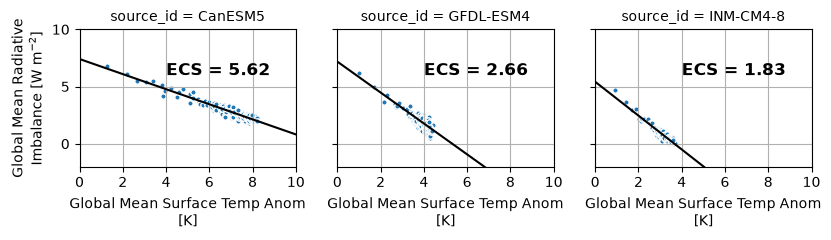

In [ ]:
### Create scatter plot for each model ###
fg = ds_abrupt.plot.scatter(x='tas', y='imbalance', col='source_id', col_wrap=3, size=2.5, s=15,
                           xlim=(0,10), ylim=(-2,10))

### Add the line of best fit and the ECS value to each panel ###
def calc_and_plot_ecs(x, y, **kwargs):
    x = x[~np.isnan(x)]
    y = y[~np.isnan(y)]
    a, b = np.polyfit(x, y, 1)
    ecs = -0.5 * b/a
    plt.autoscale(False)
    plt.plot([0, 10], np.polyval([a, b], [0, 10]), 'k')
    plt.text(4, 6, f'ECS = {ecs:3.2f}', fontdict={'weight': 'bold', 'size': 12})
    plt.grid()

fg.data = ds_abrupt
fg.map(calc_and_plot_ecs, 'tas', 'imbalance')

### Create Summary Figures

At this point it is time to investigate the ensemble mean and spread in the CMIP6 response to an abrupt quadrupling of CO$_{2}$. You will be creating a 4-panel figure. The top 2 panels will show the timeseries of the global mean temperature anomaly and radiative imbalance (ensemble mean and 95% confidence interval), while the bottom 2 panels will show the distribution of ECS across the CMIP6 models as a boxplot, and the ECS of each individual model:

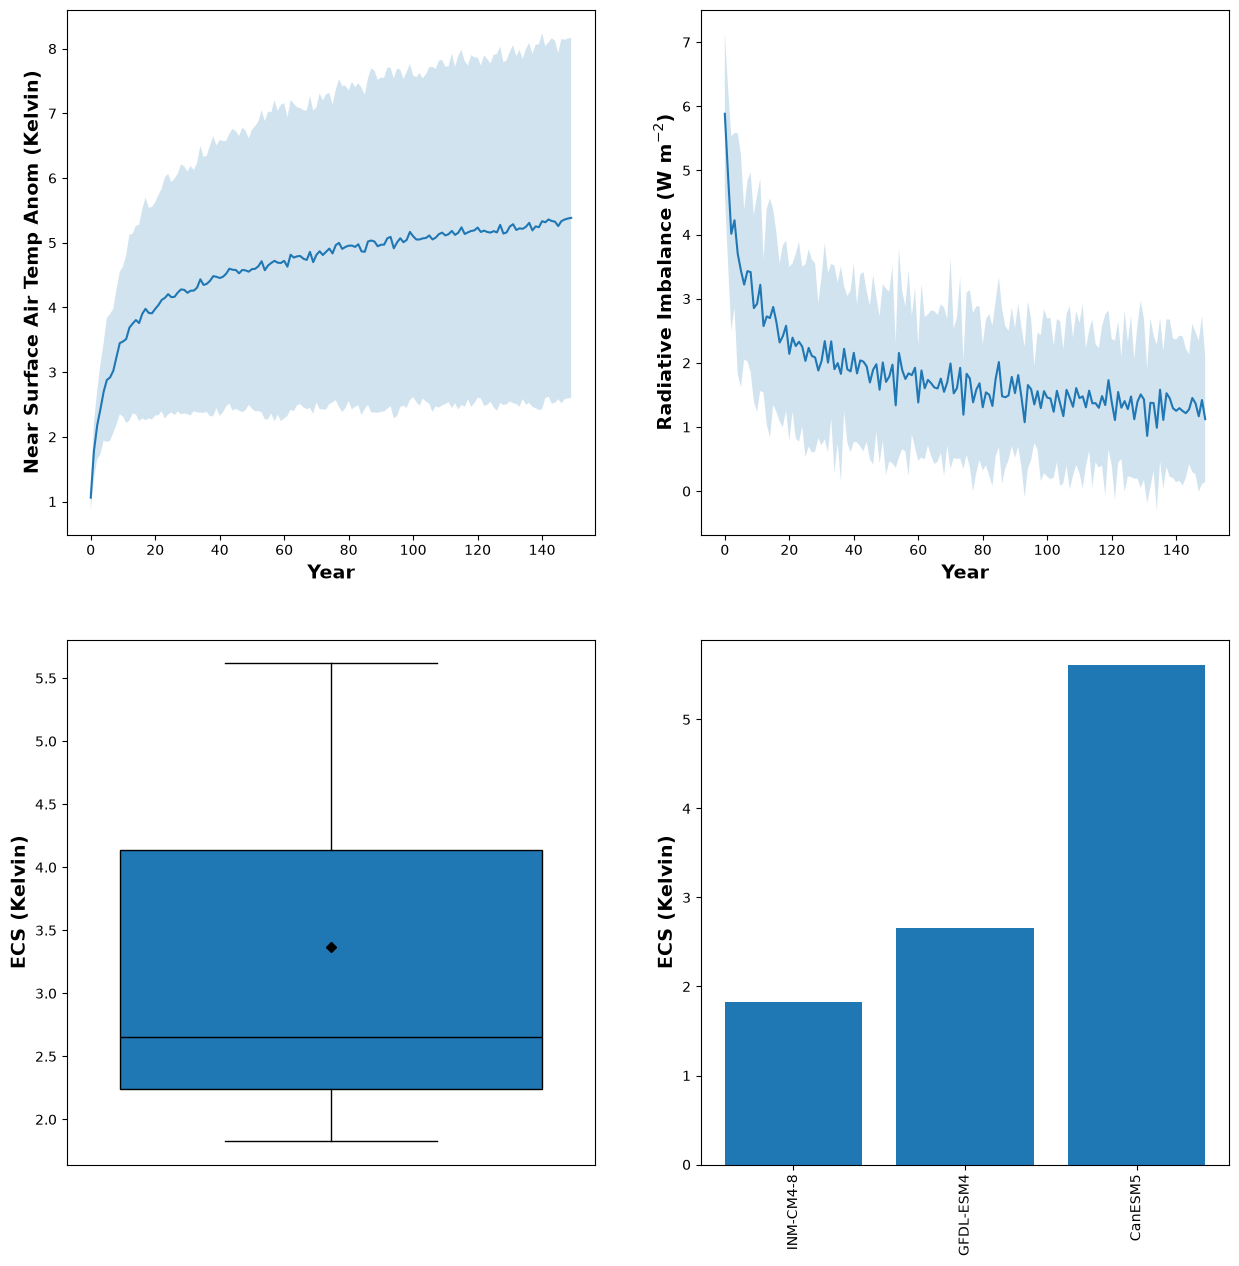

In [8]:
### Calculate the ensemble mean and 95% confidence interval ###
ds_vars = ds_abrupt[['tas', 'imbalance']]
ens_mean = ds_vars.mean('source_id')
ens_ci = 1.96 * ds_vars.std('source_id', ddof=1) / np.sqrt(ds_vars.count('source_id'))

### Sort the models from lowest to highest ECS ###
ecs_sorted = ds_abrupt.ecs.sortby(ds_abrupt.ecs)

### Create Figures ###
fig,axs = plt.subplots(nrows=2,ncols=2,figsize=(15,15)) #initialize a 4 panel figure
ax1,ax2,ax3,ax4 = axs.flat

mean_style={"marker":"D", "markerfacecolor":"black", "markeredgecolor":"black", "markersize":5} #customize the display of the ensemble mean in the boxplot
flierprops = dict(marker='d', markersize=5) #customize the display of the outliers in the boxplot

## tas timeseries ##
ax1.plot(ens_mean.year, ens_mean.tas)
ax1.fill_between(ens_mean.year, ens_mean.tas - ens_ci.tas, ens_mean.tas + ens_ci.tas, alpha=0.2) #use the 95% confidence interval
ax1.set_ylabel('Near Surface Air Temp Anom (Kelvin)',fontsize=14,fontweight='bold')
ax1.set_xlabel('Year',fontsize=14,fontweight='bold')

## imbalance timeseries ##
ax2.plot(ens_mean.year, ens_mean.imbalance)
ax2.fill_between(ens_mean.year, ens_mean.imbalance - ens_ci.imbalance, ens_mean.imbalance + ens_ci.imbalance, alpha=0.2) #use the 95% confidence interval
ax2.set_ylabel('Radiative Imbalance (W m$^{-2}$)',fontsize=14,fontweight='bold')
ax2.set_xlabel('Year',fontsize=14,fontweight='bold')

### ECS boxplot ###
ax3.boxplot(ds_abrupt.ecs.values, widths=0.8, patch_artist=True, showmeans=True, meanprops=mean_style, flierprops=flierprops,
            boxprops=dict(facecolor='tab:blue'), medianprops=dict(color='black'))
ax3.set_ylabel('ECS (Kelvin)',fontsize=14,fontweight='bold')
ax3.set_xlabel('') #no x-label needed for boxplots
ax3.set_xticks([]) #remove x-ticks

### ECS for each model ###
ax4.bar(ecs_sorted.source_id.values, ecs_sorted.values, color='tab:blue') #models are sorted from lowest to highest ECS
ax4.set_ylabel('ECS (Kelvin)',fontsize=14,fontweight='bold')
ax4.set_xlabel('') #model names are shown on the x-ticks
ax4.tick_params(axis='x', labelrotation=90) #rotate model names so they don't overlap

plt.show()

### Reflection Questions

In this module, you estimated the Equilibrium Climate Sensitivity of the CMIP6 models using the Gregory Method, applied to the `abrupt-4xCO2` experiment. We leave you with a couple of reflection questions:

1) What is the range of ECS across the CMIP6 models, and how does the ensemble mean compare to the IPCC AR6 assessed likely range of 2.5 to 4 K? What could cause some models to have a much higher ECS than others? (hint: think about the climate feedbacks discussed in the text)
2) Look back at the Gregory regression plots for the individual models. Is the relationship between the radiative imbalance and the temperature anomaly perfectly linear over the 150 years? How might this affect the ECS estimated by the Gregory Method?